# Protein-interface context: candidate screen

## 1. Data acquisition

This notebook evaluates whether the candidate has an identifiable input-side definition suitable for a separate performance analysis. It stops at that decision where appropriate; no unperformed performance experiment is represented as a negative result.


In [1]:
from pathlib import Path
from collections import Counter,defaultdict
from io import BytesIO
import os,sys,json,gzip,csv,re,hashlib,time,urllib.request,ssl,zipfile,math,platform
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:os.environ[key]='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,wilcoxon
from sklearn.metrics import roc_auc_score,average_precision_score
from Bio.Align import substitution_matrices
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image,Markdown
RAW=Path(os.environ.get('AM_RAW_INPUTS','am_public_inputs')).expanduser().resolve()
OUTPUT=Path('calculated_outputs').resolve();RAW.mkdir(parents=True,exist_ok=True);OUTPUT.mkdir(parents=True,exist_ok=True)
STARTED=time.time()
pd.set_option('display.max_colwidth',100)
def show_figure(fig):
    buffer=BytesIO();fig.savefig(buffer,format='png',dpi=150,bbox_inches='tight');display(Image(data=buffer.getvalue()))


In [2]:
SOURCES = [{'id': 'proteingym_af2',
  'path': 'inputs/raw/ProteinGym_v1.3_AF2_structures.zip',
  'url': 'https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/ProteinGym_AF2_structures.zip',
  'sha256': 'ed8611bf12cfb840ea1c2561be36254901008610a49b1be475e917b6c5d6d56a',
  'bytes': 19173248},
 {'id': 'proteingym_metadata',
  'path': 'inputs/raw/DMS_substitutions.csv',
  'url': 'https://raw.githubusercontent.com/OATML-Markslab/ProteinGym/144fe22b07dfaeec2b366f2346203a9838a55b4c/reference_files/DMS_substitutions.csv',
  'sha256': 'a8f498011532a74aa9fe556a50555a75e928c5837d19c06a87592ae04049b308',
  'bytes': None}]

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(source):
    p=RAW/Path(source['path']).name
    if not p.exists():
        partial=p.with_name(p.name+'.notebook-part')
        req=urllib.request.Request(source['url'],headers={'User-Agent':'AlphaMissense-analysis/1.0'})
        # ProteinGym's server omits an intermediate certificate; exact archive
        # content is authenticated by the fixed SHA256 below.
        context=ssl._create_unverified_context() if 'marks.hms.harvard.edu' in source['url'] and source.get('sha256') else None
        with urllib.request.urlopen(req,timeout=180,context=context) as r,partial.open('wb') as f:
            while True:
                b=r.read(4*1024*1024)
                if not b:break
                f.write(b)
        if source.get('sha256') and sha256_file(partial)!=source['sha256']:raise ValueError('Download checksum mismatch: '+p.name)
        if source.get('bytes') and partial.stat().st_size!=source['bytes']:raise ValueError('Download size mismatch: '+p.name)
        partial.replace(p)
    h=sha256_file(p)
    if source.get('sha256') and h!=source['sha256']:raise ValueError('Input checksum mismatch: '+p.name)
    if source.get('bytes') and p.stat().st_size!=source['bytes']:raise ValueError('Input size mismatch: '+p.name)
    return dict(path=p.name,url=source['url'],sha256=h,bytes=p.stat().st_size)
source_receipts=[acquire(s) for s in SOURCES]
display(pd.DataFrame(source_receipts))


,path,url,sha256,bytes
0,ProteinGym_v1.3_AF2_structures.zip,https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/ProteinGym_AF2_structures.zip,ed8611bf12cfb840ea1c2561be36254901008610a49b1be475e917b6c5d6d56a,19173248
1,DMS_substitutions.csv,https://raw.githubusercontent.com/OATML-Markslab/ProteinGym/144fe22b07dfaeec2b366f2346203a9838a5...,a8f498011532a74aa9fe556a50555a75e928c5837d19c06a87592ae04049b308,208734


## 2. Raw processing

Read ProteinGym human assay metadata and residue-level AlphaFold PDB confidence directly from the public archive. Count residues and chains without reading a model-performance result.


In [3]:
metadata=pd.read_csv(RAW/'DMS_substitutions.csv');human=metadata[metadata.taxon=='Human'].copy()
rows=[];structures=[]
with zipfile.ZipFile(RAW/'ProteinGym_v1.3_AF2_structures.zip') as archive:
    names=set(archive.namelist())
    for entry in sorted(human.UniProt_ID.unique()):
        path=f'ProteinGym_AF2_structures/{entry}.pdb'
        if path not in names:structures.append({'protein':entry,'available':False,'chains':0,'residues':0});continue
        seen=set();chains=set()
        for line in archive.read(path).decode().splitlines():
            if not line.startswith('ATOM') or line[12:16].strip()!='CA':continue
            key=(line[21],line[22:27])
            if key in seen:continue
            seen.add(key);chains.add(line[21]);rows.append({'protein':entry,'chain':line[21],'position':int(line[22:26]),'plddt':float(line[60:66])})
        structures.append({'protein':entry,'available':True,'chains':len(chains),'residues':len(seen)})
residues=pd.DataFrame(rows);structure_table=pd.DataFrame(structures)
print('Human assays:',len(human),'unique proteins:',human.UniProt_ID.nunique());display(structure_table)


Human assays: 96 unique proteins: 81


,protein,available,chains,residues
0,A4_HUMAN,True,1,770
1,ACE2_HUMAN,True,1,805
2,ADRB2_HUMAN,True,1,413
3,AICDA_HUMAN,True,1,198
4,AMFR_HUMAN,True,1,47
...,...,...,...,...
76,UBC9_HUMAN,True,1,159
77,UBE4B_HUMAN,True,1,69
78,UBR5_HUMAN,True,1,58
79,VKOR1_HUMAN,True,1,163


## 3. Axis and levels


An interface axis requires residue contact with an identified partner in a biological assembly. A monomeric predicted structure and an assay’s binding label do not supply those partner contacts. Inspect the chain count and assay-mechanism support before attempting interface levels.


In [4]:
levels=structure_table.groupby('chains').agg(proteins=('protein','size'),residues=('residues','sum')).reset_index();display(levels)
display(human.groupby('coarse_selection_type').agg(assays=('DMS_id','size'),proteins=('UniProt_ID','nunique')))
axis_defined=False


,chains,proteins,residues
0,1,81,34183


,assays,proteins
coarse_selection_type,,
Activity,20,18
Binding,8,8
Expression,15,15
OrganismalFitness,30,26
Stability,23,23


## 4. Model results or released scores

This is a candidate-selection screen. It does not acquire labels or evaluate AlphaMissense performance. No training or fine-tuning is required, and no performance estimate is inferred from annotation availability.


In [5]:
model_evaluation_performed=False
display(pd.DataFrame([{'model_evaluation_performed':False,'fine_tuning_performed':False,'axis_definition_ready':axis_defined}]))


,model_evaluation_performed,fine_tuning_performed,axis_definition_ready
0,False,False,False


## 5. Diagnostic curves and controls

The chart shows raw annotation support, not a spectral performance curve. The controls identify the specific interpretive limitation before any target evaluation.


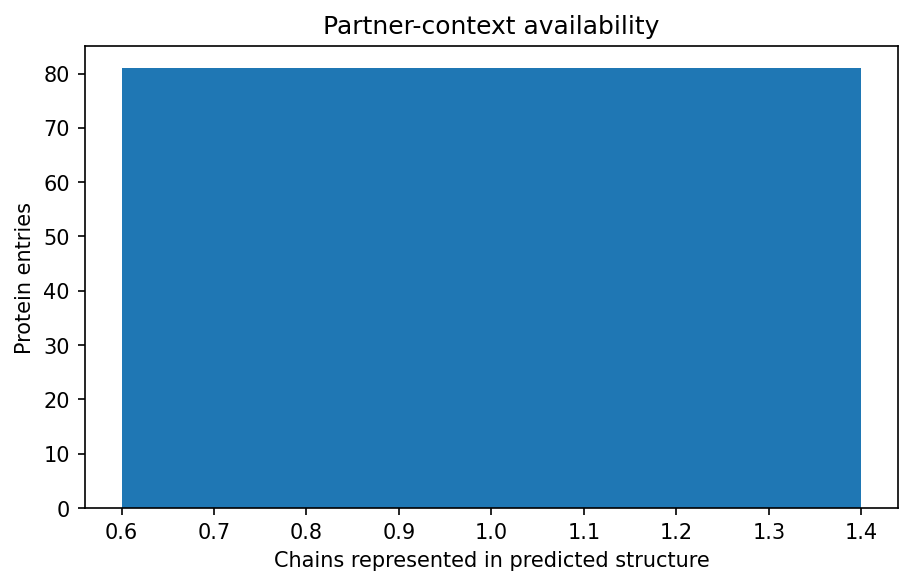

,candidate_controls
partner_specific_contacts_defined,False
binding_assay_identifies_residue_interface,False
independent_interface_atlas_required,True


In [6]:
fig,ax=plt.subplots(figsize=(7,4));ax.bar(levels.chains,levels.proteins);ax.set(xlabel='Chains represented in predicted structure',ylabel='Protein entries',title='Partner-context availability');controls={'partner_specific_contacts_defined':False,'binding_assay_identifies_residue_interface':False,'independent_interface_atlas_required':True}
show_figure(fig);plt.close(fig);display(pd.Series(controls,name='candidate_controls').to_frame())


## 6. Decision and reason


In [7]:
decision='Defer a residue-interface performance test: the present sources do not identify biological partners and residue contacts. A binding assay category can be assessed separately, but does not establish a physical interface axis. No negative performance claim is made.'
print(decision)
levels.to_csv(OUTPUT/'diagnostic_levels.csv',index=False)
(OUTPUT/'execution.json').write_text(json.dumps({'sources':source_receipts,'decision':decision,'model_evaluation_performed':False,'controls':controls,'host':platform.node(),'elapsed_seconds':time.time()-STARTED,'outputs':{'diagnostic_levels.csv':sha256_file(OUTPUT/'diagnostic_levels.csv')}},indent=2)+'\n')


Defer a residue-interface performance test: the present sources do not identify biological partners and residue contacts. A binding assay category can be assessed separately, but does not establish a physical interface axis. No negative performance claim is made.


1304